In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer, load_wine

# Veri Setlerini Yükleme
cancer_raw = load_breast_cancer()
wine_raw = load_wine()

# DataFrame Oluşturma
X_cancer = pd.DataFrame(cancer_raw.data, columns=cancer_raw.feature_names)
y_cancer = pd.Series(cancer_raw.target, name="target")

X_wine = pd.DataFrame(wine_raw.data, columns=wine_raw.feature_names)
y_wine = pd.Series(wine_raw.target, name="target")

print(" Breast Cancer Boyutu:", X_cancer.shape)
print(" Wine Boyutu:", X_wine.shape)
print("\nVeriler başarıyla yüklendi!")

 Breast Cancer Boyutu: (569, 30)
 Wine Boyutu: (178, 13)

Veriler başarıyla yüklendi!


In [8]:
def check_quality_and_stats(df, name):
    print("=" * 70)
    print(f"{name.upper()} DATASET QUALITY CHECKS & DESCRIPTIVE STATISTICS")
    print("=" * 70)
    missing_count = df.isnull().sum().sum()
    duplicate_count = df.duplicated().sum()
    print(f"Missing Values Count: {missing_count}")
    print(f"Duplicate Rows Count: {duplicate_count}")
    print("\nData Types Count:")
    print(df.dtypes.value_counts().to_string())
    print(f"Numerical Features: {df.shape[1]}, Categorical Features: 0")
    stats = df.describe().T[['mean', 'std', 'min', '50%', 'max', '25%', '75%']].copy()
    stats.columns = ['Mean', 'Std', 'Min', 'Median', 'Max', 'Q1', 'Q3']
    print("\nDescriptive Statistics:")
    print(stats.round(3).to_string())
    return stats

stats_cancer = check_quality_and_stats(X_cancer, "Breast Cancer")
print("\n")
stats_wine = check_quality_and_stats(X_wine, "Wine")

BREAST CANCER DATASET QUALITY CHECKS & DESCRIPTIVE STATISTICS
Missing Values Count: 0
Duplicate Rows Count: 0

Data Types Count:
float64    30
Numerical Features: 30, Categorical Features: 0

Descriptive Statistics:
                            Mean      Std      Min   Median       Max       Q1        Q3
mean radius               14.127    3.524    6.981   13.370    28.110   11.700    15.780
mean texture              19.290    4.301    9.710   18.840    39.280   16.170    21.800
mean perimeter            91.969   24.299   43.790   86.240   188.500   75.170   104.100
mean area                654.889  351.914  143.500  551.100  2501.000  420.300   782.700
mean smoothness            0.096    0.014    0.053    0.096     0.163    0.086     0.105
mean compactness           0.104    0.053    0.019    0.093     0.345    0.065     0.130
mean concavity             0.089    0.080    0.000    0.062     0.427    0.030     0.131
mean concave points        0.049    0.039    0.000    0.034     0.201   

C:\Users\AslıhanTanyeli\AppData\Local\Temp\ipykernel_38028\1887117746.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_cancer, ax=axes[0], palette="Blues_d")
C:\Users\AslıhanTanyeli\AppData\Local\Temp\ipykernel_38028\1887117746.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_wine, ax=axes[1], palette="Greens_d")


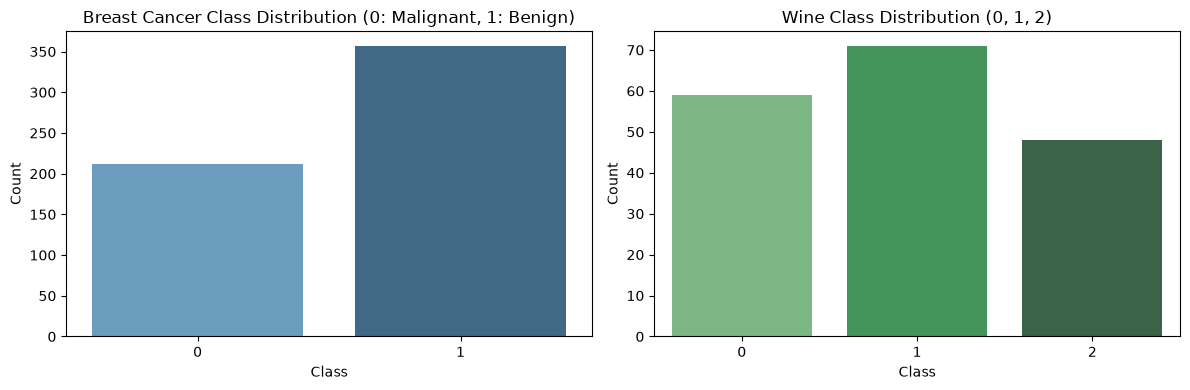

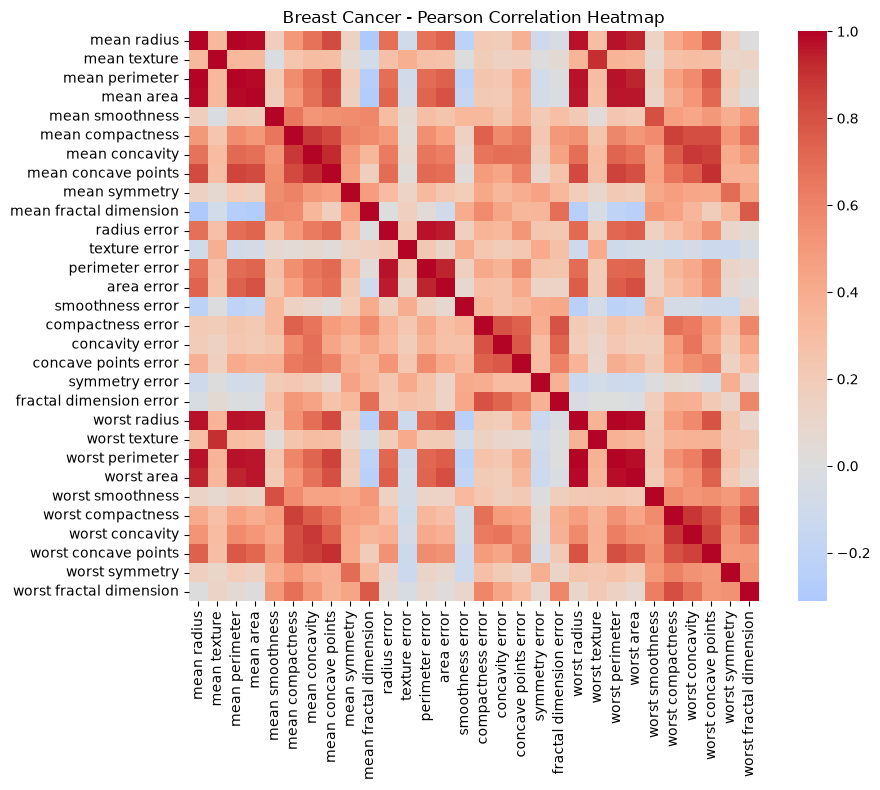


--- Top 3 Correlation Pairs (Breast Cancer) ---
  mean perimeter <-> mean radius: 0.9979
  worst perimeter <-> worst radius: 0.9937
  mean area <-> mean radius: 0.9874


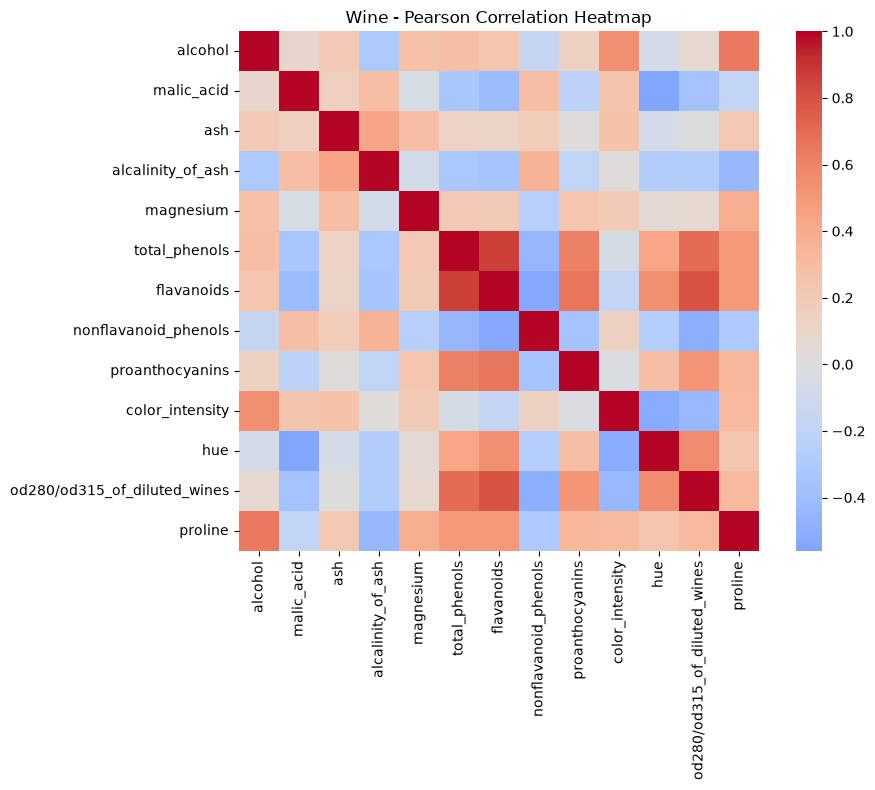


--- Top 3 Correlation Pairs (Wine) ---
  flavanoids <-> total_phenols: 0.8646
  od280/od315_of_diluted_wines <-> flavanoids: 0.7872
  od280/od315_of_diluted_wines <-> total_phenols: 0.6999


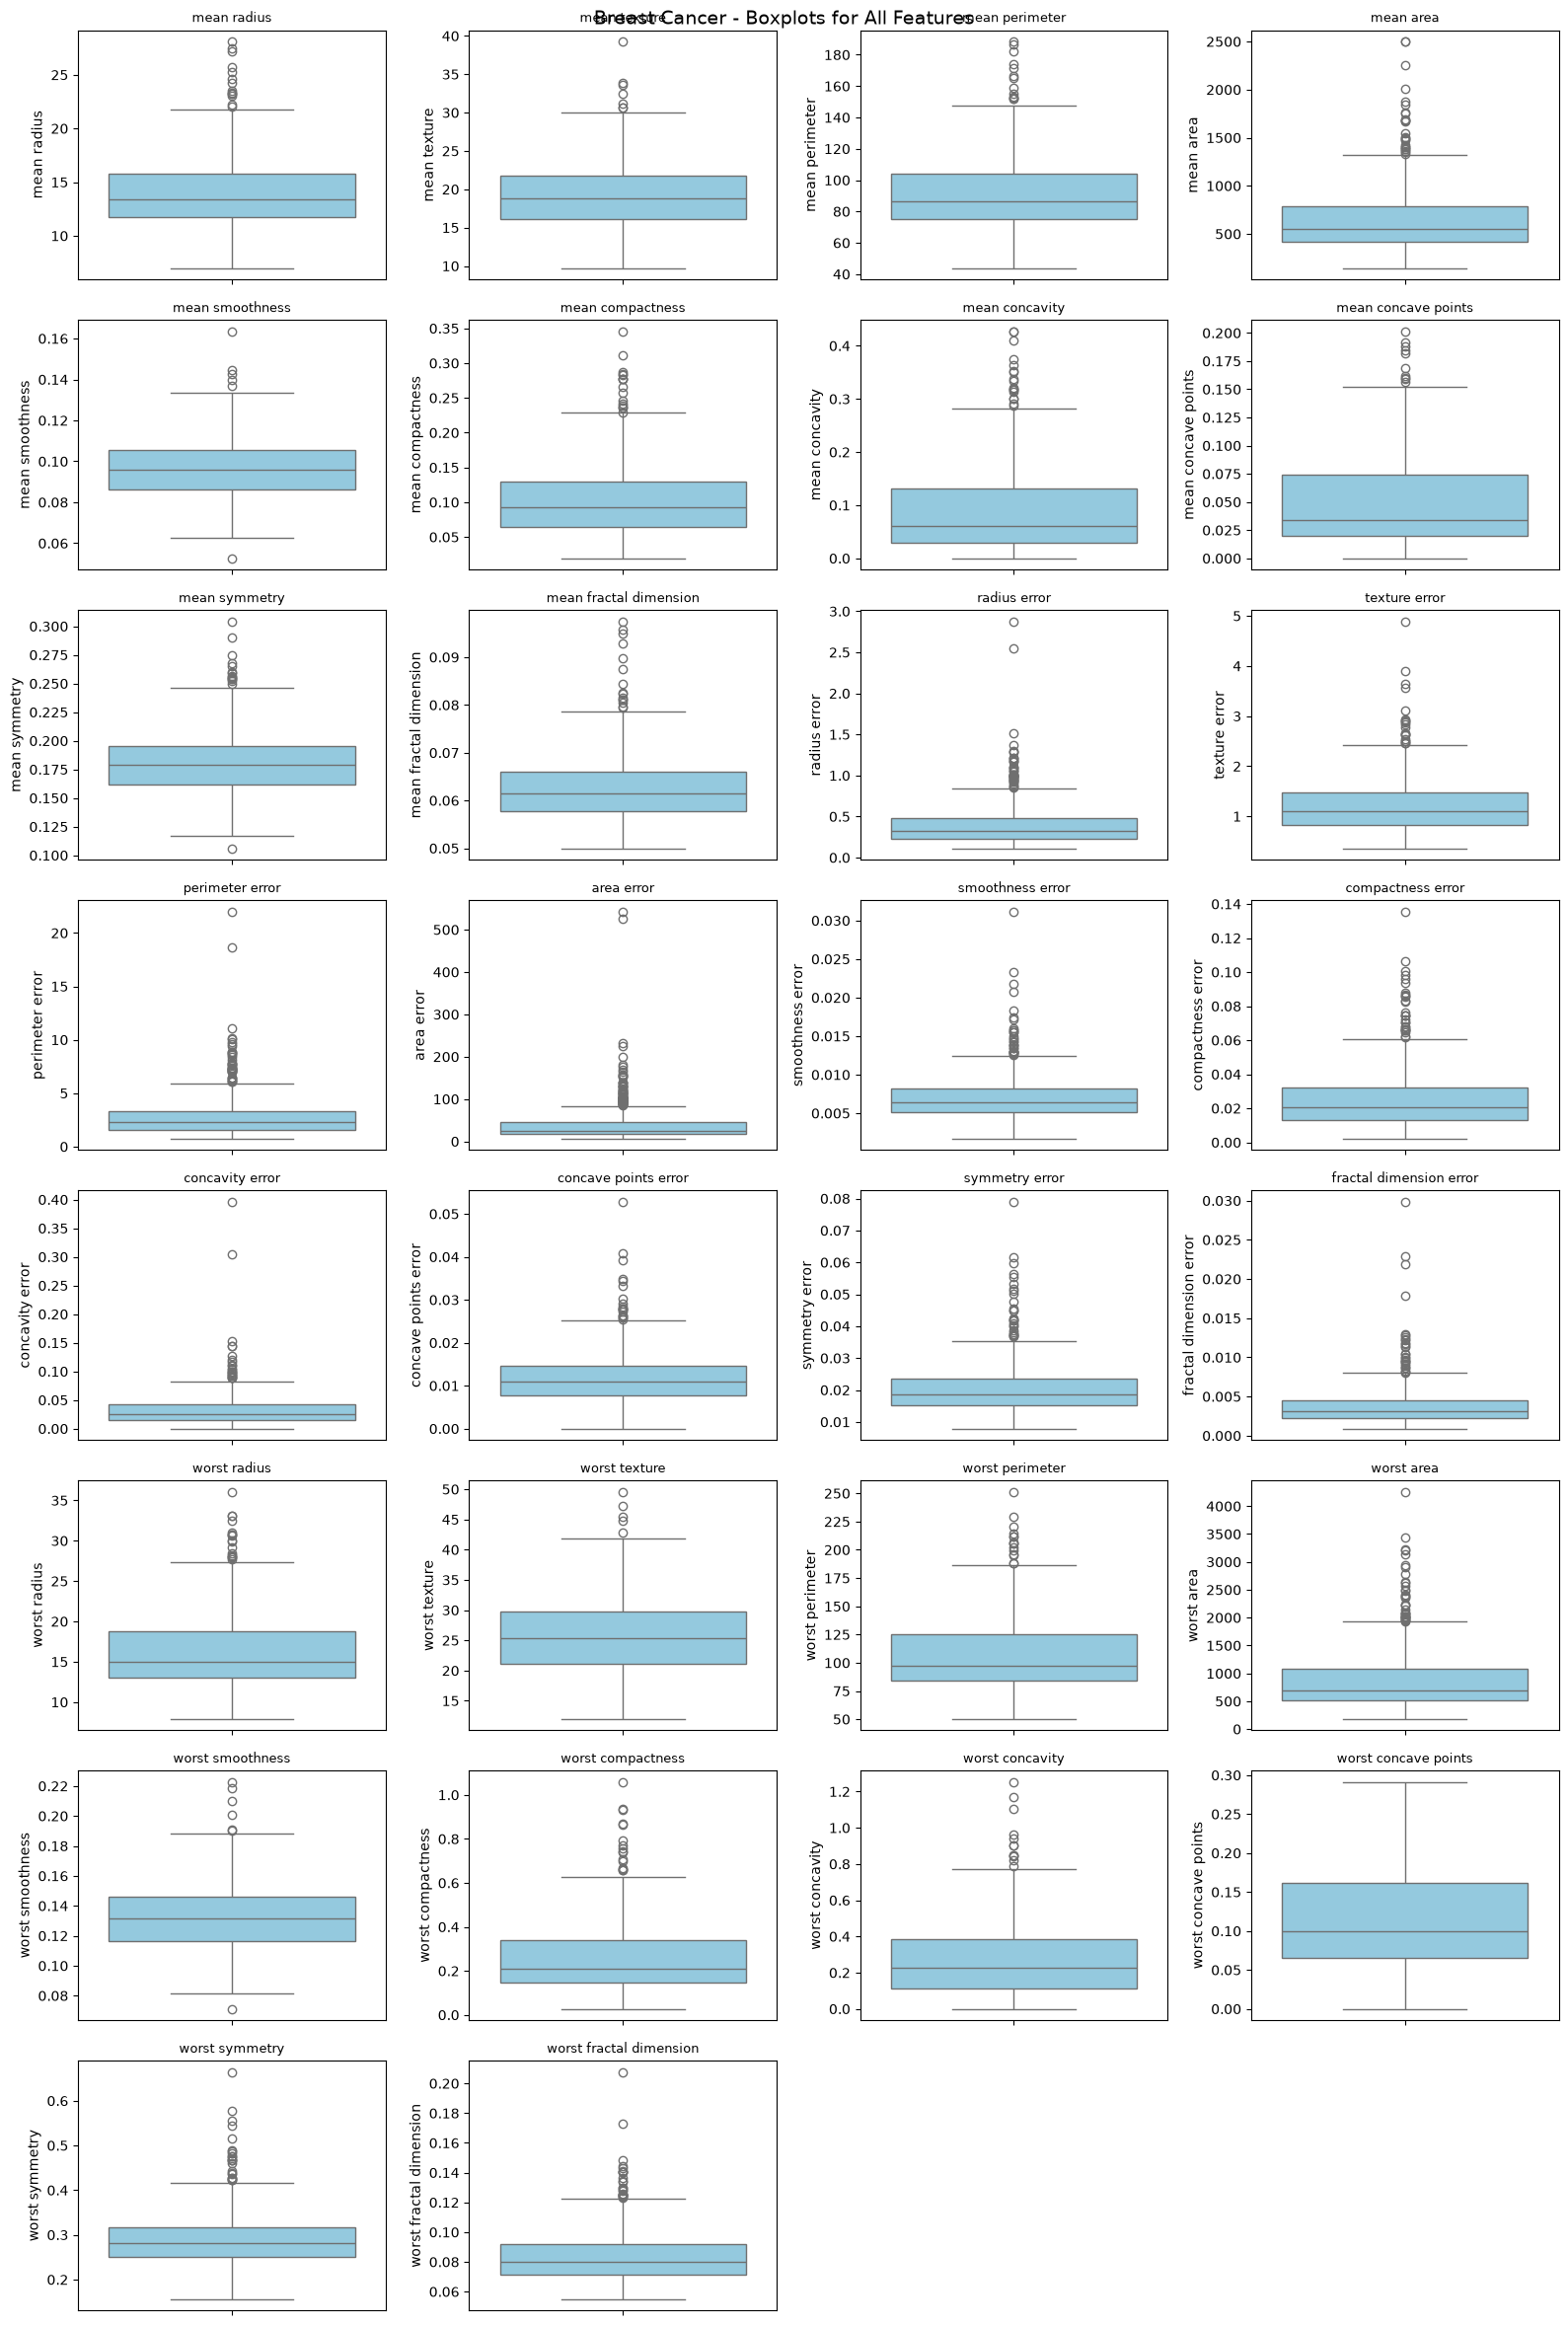

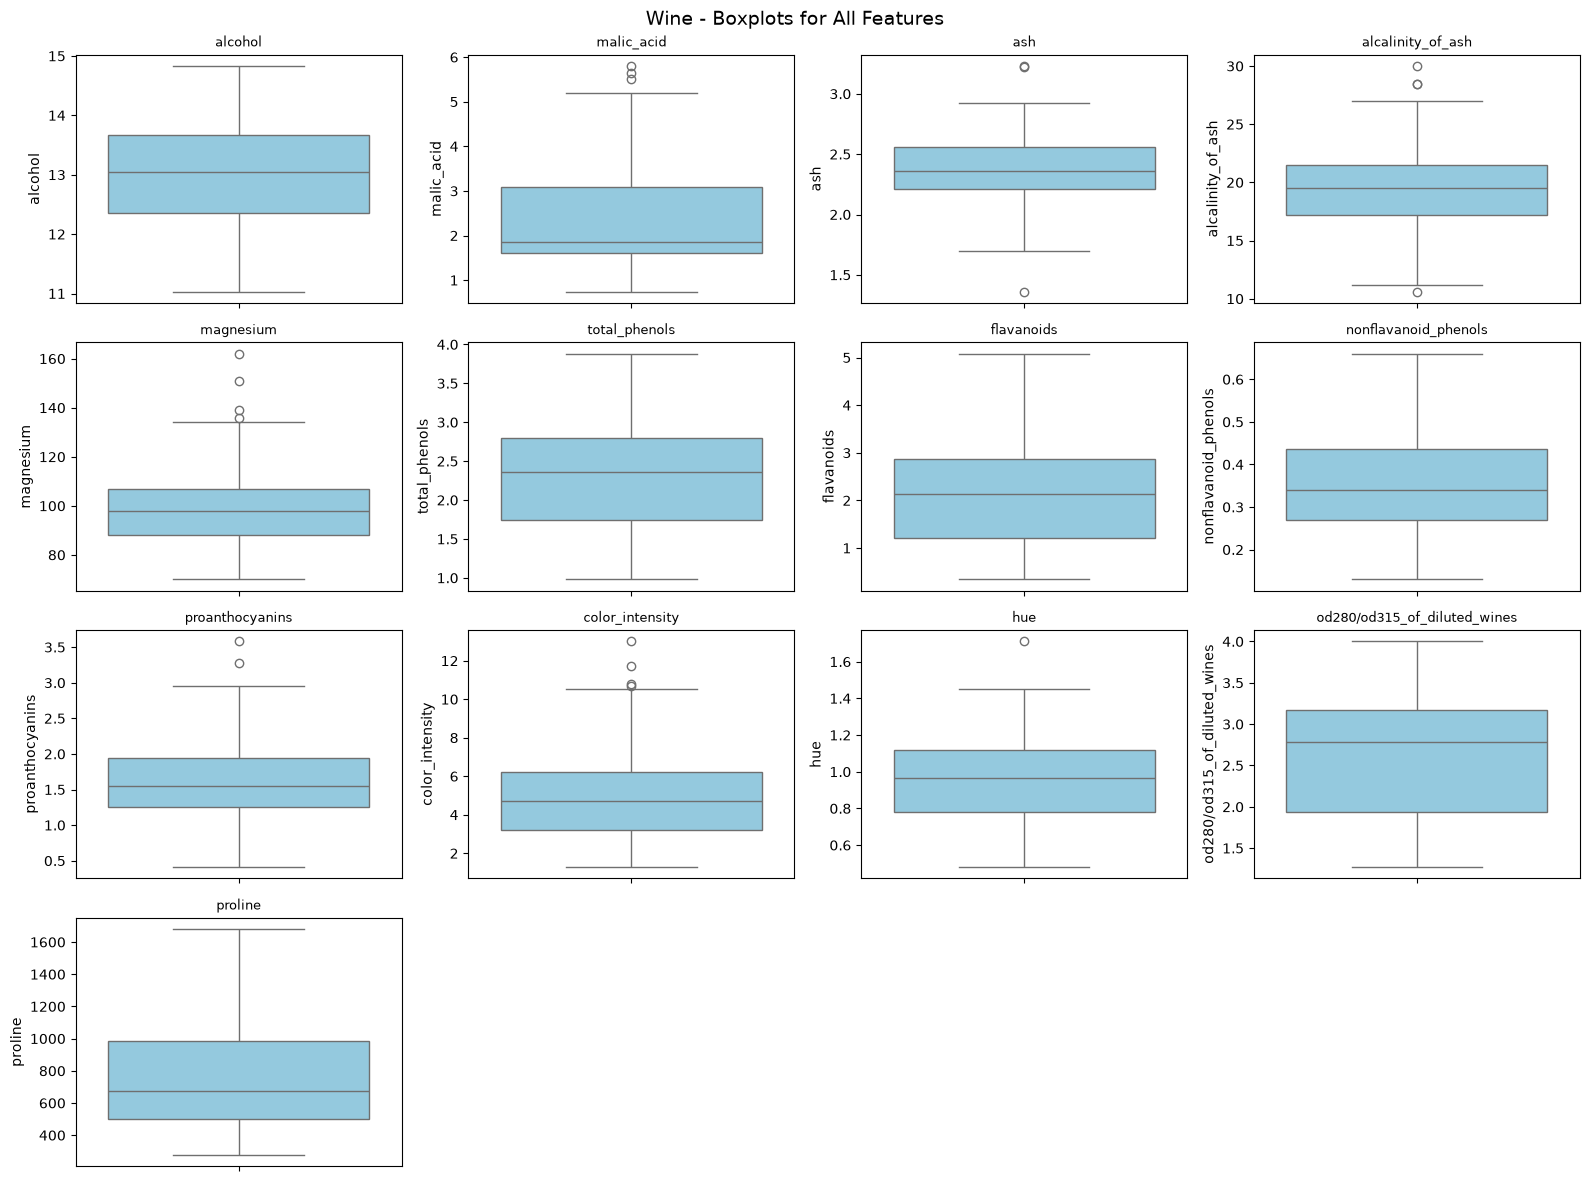

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=y_cancer, ax=axes[0], palette="Blues_d")
axes[0].set_title("Breast Cancer Class Distribution (0: Malignant, 1: Benign)")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Count")

sns.countplot(x=y_wine, ax=axes[1], palette="Greens_d")
axes[1].set_title("Wine Class Distribution (0, 1, 2)")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

def plot_heatmap_and_top_corrs(df, name):
    corr = df.corr()
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, cmap="coolwarm", center=0, square=True, annot=False)
    plt.title(f"{name} - Pearson Correlation Heatmap")
    plt.tight_layout()
    plt.show()
    
    upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    top3 = upper.unstack().abs().sort_values(ascending=False).head(3)
    print(f"\n--- Top 3 Correlation Pairs ({name}) ---")
    for (col1, col2), val in top3.items():
        actual_val = corr.loc[col1, col2]
        print(f"  {col1} <-> {col2}: {actual_val:.4f}")

plot_heatmap_and_top_corrs(X_cancer, "Breast Cancer")
plot_heatmap_and_top_corrs(X_wine, "Wine")

def plot_boxplots(df, name):
    num_cols = len(df.columns)
    rows = (num_cols + 3) // 4
    fig, axes = plt.subplots(rows, 4, figsize=(16, rows * 3))
    axes = axes.flatten()
    for i, col in enumerate(df.columns):
        sns.boxplot(y=df[col], ax=axes[i], color="skyblue")
        axes[i].set_title(col, fontsize=9)
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')
    plt.suptitle(f"{name} - Boxplots for All Features", fontsize=14)
    plt.tight_layout()
    plt.show()

plot_boxplots(X_cancer, "Breast Cancer")
plot_boxplots(X_wine, "Wine")

In [15]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEEDS = [42, 52, 62]
split_records = []
held_out_data = {}

for name, (X, y) in [("cancer", (X_cancer, y_cancer)), ("wine", (X_wine, y_wine))]:
    X_tv, X_test, y_tv, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=42
    )
    held_out_data[name] = (X_tv, X_test, y_tv, y_test)
    
    for seed in SEEDS:
        X_tr, X_va, y_tr, y_va = train_test_split(
            X_tv, y_tv, test_size=0.125, stratify=y_tv, random_state=seed
        )
        split_records.append({"dataset": name, "seed": seed, "subset": "train", "count": len(X_tr), "percentage": len(X_tr)/len(X)*100})
        split_records.append({"dataset": name, "seed": seed, "subset": "val", "count": len(X_va), "percentage": len(X_va)/len(X)*100})
        split_records.append({"dataset": name, "seed": seed, "subset": "test", "count": len(X_test), "percentage": len(X_test)/len(X)*100})

df_split_summary = pd.DataFrame(split_records)
print("=== DATASET SPLIT SUMMARY ===")
print(df_split_summary.to_string(index=False))

scaler_demo = StandardScaler()
X_tr_demo, X_va_demo, y_tr_demo, y_va_demo = train_test_split(
    held_out_data["cancer"][0], held_out_data["cancer"][2], test_size=0.125, stratify=held_out_data["cancer"][2], random_state=42
)
print("\n=== CANCER TRAIN FEATURES BEFORE SCALING (SEED 42 - FIRST 5 ROWS) ===")
print(X_tr_demo.head().round(3).to_string())

X_tr_demo_scaled = scaler_demo.fit_transform(X_tr_demo)
df_tr_demo_scaled = pd.DataFrame(X_tr_demo_scaled, columns=X_tr_demo.columns)
print("\n=== CANCER TRAIN FEATURES AFTER SCALING (SEED 42 - FIRST 5 ROWS) ===")
print(df_tr_demo_scaled.head().round(3).to_string())

=== DATASET SPLIT SUMMARY ===
dataset  seed subset  count  percentage
 cancer    42  train    398   69.947276
 cancer    42    val     57   10.017575
 cancer    42   test    114   20.035149
 cancer    52  train    398   69.947276
 cancer    52    val     57   10.017575
 cancer    52   test    114   20.035149
 cancer    62  train    398   69.947276
 cancer    62    val     57   10.017575
 cancer    62   test    114   20.035149
   wine    42  train    124   69.662921
   wine    42    val     18   10.112360
   wine    42   test     36   20.224719
   wine    52  train    124   69.662921
   wine    52    val     18   10.112360
   wine    52   test     36   20.224719
   wine    62  train    124   69.662921
   wine    62    val     18   10.112360
   wine    62   test     36   20.224719

=== CANCER TRAIN FEATURES BEFORE SCALING (SEED 42 - FIRST 5 ROWS) ===
     mean radius  mean texture  mean perimeter  mean area  mean smoothness  mean compactness  mean concavity  mean concave points  mean sym

In [6]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

cancer_raw = load_breast_cancer()
wine_raw = load_wine()

X_cancer = pd.DataFrame(cancer_raw.data, columns=cancer_raw.feature_names)
y_cancer = pd.Series(cancer_raw.target, name="target")

X_wine = pd.DataFrame(wine_raw.data, columns=wine_raw.feature_names)
y_wine = pd.Series(wine_raw.target, name="target")

SEEDS = [42, 52, 62]
held_out_data = {}

for name, (X, y) in [("cancer", (X_cancer, y_cancer)), ("wine", (X_wine, y_wine))]:
    X_tv, X_test, y_tv, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=42
    )
    held_out_data[name] = (X_tv, X_test, y_tv, y_test)

results = []

for name, (X, y, is_binary) in [("cancer", (X_cancer, y_cancer, True)), ("wine", (X_wine, y_wine, False))]:
    X_tv, X_test, y_tv, y_test = held_out_data[name]
    
    for seed in SEEDS:
        X_tr, X_va, y_tr, y_va = train_test_split(
            X_tv, y_tv, test_size=0.125, stratify=y_tv, random_state=seed
        )
        
        scaler = StandardScaler()
        X_tr_s = scaler.fit_transform(X_tr)
        X_va_s = scaler.transform(X_va)
        
        representations = {
            "unscaled": (X_tr.values, X_va.values),
            "scaled": (X_tr_s, X_va_s)
        }
        
        model_configs = []
        for depth in [2, 3, 5, 10, None]:
            model_configs.append(("DecisionTree", f"max_depth={depth}"))
        for k in [1, 3, 5, 7, 11]:
            model_configs.append(("KNN", f"k={k}"))
        model_configs.append(("GaussianNB", "default"))
        
        for rep_name, (X_train_data, X_val_data) in representations.items():
            for alg_name, param_str in model_configs:
                if alg_name == "DecisionTree":
                    d_val = None if param_str == "max_depth=None" else int(param_str.split("=")[1])
                    model = DecisionTreeClassifier(max_depth=d_val, random_state=seed)
                elif alg_name == "KNN":
                    k_val = int(param_str.split("=")[1])
                    model = KNeighborsClassifier(n_neighbors=k_val)
                elif alg_name == "GaussianNB":
                    model = GaussianNB()
                
                model.fit(X_train_data, y_tr)
                
                tr_pred = model.predict(X_train_data)
                va_pred = model.predict(X_val_data)
                
                tr_acc = accuracy_score(y_tr, tr_pred)
                tr_f1 = f1_score(y_tr, tr_pred, average="macro", zero_division=0)
                
                va_acc = accuracy_score(y_va, va_pred)
                va_prec = precision_score(y_va, va_pred, average="macro", zero_division=0)
                va_rec = recall_score(y_va, va_pred, average="macro", zero_division=0)
                va_f1 = f1_score(y_va, va_pred, average="macro", zero_division=0)
                
                if is_binary:
                    va_proba = model.predict_proba(X_val_data)[:, 0]
                    va_auc = roc_auc_score(y_va == 0, va_proba)
                else:
                    va_proba = model.predict_proba(X_val_data)
                    va_auc = roc_auc_score(y_va, va_proba, multi_class="ovr", average="macro")
                
                run_id = f"{name}_{alg_name.lower()}_{rep_name}_{param_str}_s{seed}"
                
                results.append({
                    "run_id": run_id,
                    "dataset": name,
                    "seed": seed,
                    "algorithm": alg_name,
                    "representation": rep_name,
                    "parameters": param_str,
                    "train_accuracy": tr_acc,
                    "train_macro_f1": tr_f1,
                    "val_accuracy": va_acc,
                    "val_macro_precision": va_prec,
                    "val_macro_recall": va_rec,
                    "val_macro_f1": va_f1,
                    "val_roc_auc": va_auc
                })

df_runs = pd.DataFrame(results)
df_runs.to_csv("classifier_runs.csv", index=False)

metrics_to_aggregate = ["train_accuracy", "train_macro_f1", "val_accuracy", "val_macro_precision", "val_macro_recall", "val_macro_f1", "val_roc_auc"]
df_summary = df_runs.groupby(["dataset", "algorithm", "representation", "parameters"])[metrics_to_aggregate].agg(["mean", "std"]).reset_index()
df_summary.columns = [f"{col[0]}_{col[1]}" if col[1] else col[0] for col in df_summary.columns]
df_summary = df_summary.sort_values(["dataset", "val_macro_f1_mean", "val_macro_f1_std"], ascending=[True, False, True]).reset_index(drop=True)
df_summary.to_csv("classifier_summary.csv", index=False)

print("classifier_runs.csv and classifier_summary.csv saved successfully!")

classifier_runs.csv and classifier_summary.csv saved successfully!



=== FINAL TEST EVALUATION: CANCER ===
Selected Model: KNN (scaled, k=7)
Test Accuracy: 0.9737
Test Macro-F1: 0.9713
Test ROC-AUC: 0.9888


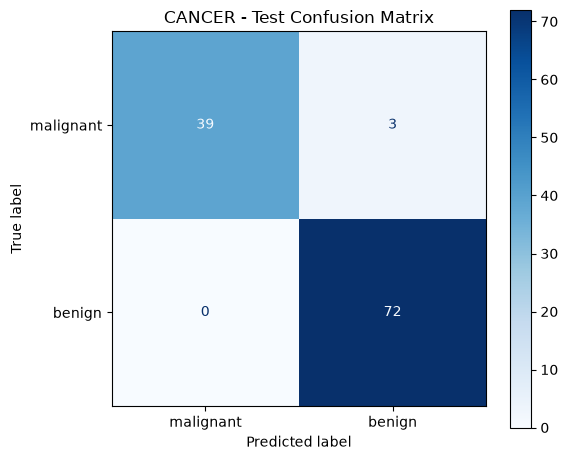


=== FINAL TEST EVALUATION: WINE ===
Selected Model: KNN (scaled, k=11)
Test Accuracy: 1.0000
Test Macro-F1: 1.0000
Test ROC-AUC: 1.0000


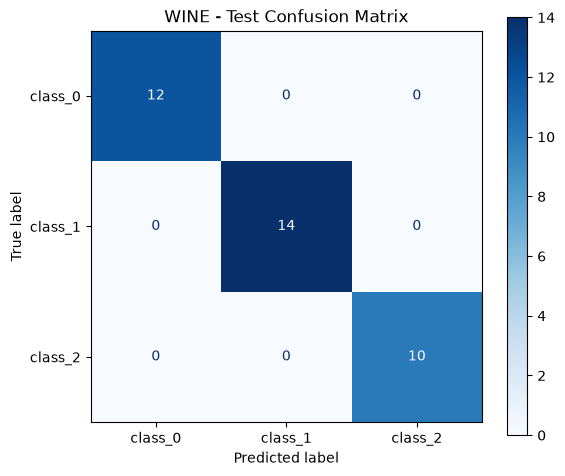

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve
from sklearn.preprocessing import label_binarize

df_summary = pd.read_csv("classifier_summary.csv")
test_results = []

for name in ["cancer", "wine"]:
    best_config = df_summary[df_summary["dataset"] == name].iloc[0]
    X_tv, X_test, y_tv, y_test = held_out_data[name]
    
    X_tr, X_va, y_tr, y_va = train_test_split(
        X_tv, y_tv, test_size=0.125, stratify=y_tv, random_state=42
    )
    
    is_scaled = (best_config["representation"] == "scaled")
    scaler = StandardScaler()
    if is_scaled:
        X_tr_fit = scaler.fit_transform(X_tr)
        X_te_fit = scaler.transform(X_test)
    else:
        X_tr_fit = X_tr.values
        X_te_fit = X_test.values
        
    alg_name = best_config["algorithm"]
    param_str = str(best_config["parameters"])
    
    if alg_name == "DecisionTree":
        d_val = None if "None" in param_str else int(param_str.split("=")[1])
        model = DecisionTreeClassifier(max_depth=d_val, random_state=42)
    elif alg_name == "KNN":
        k_val = int(param_str.split("=")[1])
        model = KNeighborsClassifier(n_neighbors=k_val)
    elif alg_name == "GaussianNB":
        model = GaussianNB()
        
    model.fit(X_tr_fit, y_tr)
    te_pred = model.predict(X_te_fit)
    te_proba = model.predict_proba(X_te_fit)
    
    te_acc = accuracy_score(y_test, te_pred)
    te_prec = precision_score(y_test, te_pred, average="macro", zero_division=0)
    te_rec = recall_score(y_test, te_pred, average="macro", zero_division=0)
    te_f1 = f1_score(y_test, te_pred, average="macro", zero_division=0)
    
    if name == "cancer":
        te_auc = roc_auc_score(y_test == 0, te_proba[:, 0])
    else:
        te_auc = roc_auc_score(y_test, te_proba, multi_class="ovr", average="macro")
        
    test_results.append({
        "dataset": name,
        "selected_configuration": f"{alg_name}_{best_config['representation']}_{param_str}",
        "evaluation_seed": 42,
        "val_macro_f1_mean": best_config["val_macro_f1_mean"],
        "val_macro_f1_std": best_config["val_macro_f1_std"],
        "test_accuracy": te_acc,
        "test_macro_precision": te_prec,
        "test_macro_recall": te_rec,
        "test_macro_f1": te_f1,
        "test_roc_auc": te_auc
    })
    
    print(f"\n=== FINAL TEST EVALUATION: {name.upper()} ===")
    print(f"Selected Model: {alg_name} ({best_config['representation']}, {param_str})")
    print(f"Test Accuracy: {te_acc:.4f}")
    print(f"Test Macro-F1: {te_f1:.4f}")
    print(f"Test ROC-AUC: {te_auc:.4f}")
    
    cm = confusion_matrix(y_test, te_pred)
    fig, ax = plt.subplots(figsize=(6, 5))
    disp_labels = ["malignant", "benign"] if name == "cancer" else ["class_0", "class_1", "class_2"]
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=disp_labels)
    disp.plot(ax=ax, cmap="Blues")
    ax.set_title(f"{name.upper()} - Test Confusion Matrix")
    plt.tight_layout()
    plt.show()

df_classifier_test = pd.DataFrame(test_results)
df_classifier_test.to_csv("classifier_test.csv", index=False)

In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

kmeans_runs = []
kmeans_test = []

for name, k_clusters in [("cancer", 2), ("wine", 3)]:
    X_tv, X_test, y_tv, y_test = held_out_data[name]
    
    for seed in SEEDS:
        X_tr, X_va, y_tr, y_va = train_test_split(
            X_tv, y_tv, test_size=0.125, stratify=y_tv, random_state=seed
        )
        scaler = StandardScaler()
        X_tr_s = scaler.fit_transform(X_tr)
        X_va_s = scaler.transform(X_va)
        
        reps = {
            "unscaled": (X_tr.values, X_va.values),
            "scaled": (X_tr_s, X_va_s)
        }
        
        for rep_name, (X_tr_d, X_va_d) in reps.items():
            km = KMeans(n_clusters=k_clusters, n_init=10, random_state=seed)
            km.fit(X_tr_d)
            va_clusters = km.predict(X_va_d)
            
            inertia = km.inertia_
            ari = adjusted_rand_score(y_va, va_clusters)
            sil = silhouette_score(X_va_d, va_clusters) if len(np.unique(va_clusters)) > 1 else np.nan
            
            kmeans_runs.append({
                "dataset": name,
                "seed": seed,
                "representation": rep_name,
                "training_inertia": inertia,
                "val_ari": ari,
                "val_silhouette": sil
            })

df_kmeans_runs = pd.DataFrame(kmeans_runs)
df_kmeans_runs.to_csv("kmeans_runs.csv", index=False)

df_kmeans_summary = df_kmeans_runs.groupby(["dataset", "representation"]).agg({
    "training_inertia": ["mean", "std"],
    "val_ari": ["mean", "std"],
    "val_silhouette": ["mean", "std", "count"]
}).reset_index()

df_kmeans_summary.columns = [f"{c[0]}_{c[1]}" if c[1] else c[0] for c in df_kmeans_summary.columns]
df_kmeans_summary.to_csv("kmeans_summary.csv", index=False)

print("K-Means clustering analysis complete and CSV files saved!")

K-Means clustering analysis complete and CSV files saved!
